In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}  # stoi: string to integer
stoi["."] = 0  # add a special token to represent the start/end of a word
itos = {i: s for s, i in stoi.items()}  # itos: integer to string
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [103]:
# build the dataset

block_size = (
    3  # context length: how many characters do we take to predict the next one?
)
X, Y = [], []
for w in words:
    # print(w)
    context = [0] * block_size  # initialize the context with all start-of-word tokens
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print("".join(itos[i] for i in context), "----->", itos[ix])
        context = context[1:] + [ix]  # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

In [104]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [7]:
C = torch.randn((27, 2))  # 27 characters, 2-dimensional representation

In [ ]:
emb = C[
    X
]  # (32, 3, 2) 32 examples, 3 characters in context, 2-dimensional representation
emb.shape

torch.Size([32, 3, 2])

In [24]:
W1 = torch.randn(
    (6, 100)
)  # 6 inputs (3*2) because 2 dimensions per character and 3 embeddings, 100 outputs
b1 = torch.randn(100)  # 100 outputs

In [65]:
h = torch.tanh(
    emb.view(-1, 6) @ W1 + b1
)  # -1 means "figure out the size of this dimension based on the other dimensions and the total number of elements" or alternatively use emb.shape[0] to get the number of examples. (32, 6) @ (6, 100) + (100,) = (32, 100)

In [66]:
h

tensor([[-0.4190,  0.9019, -0.9665,  ..., -0.1035, -0.8466, -0.0857],
        [ 0.9890, -0.9683, -0.9986,  ...,  0.9928,  0.8089, -0.6019],
        [-0.9742, -0.9994,  0.1338,  ...,  0.7329, -0.9676, -1.0000],
        ...,
        [-0.9796, -1.0000, -0.8720,  ...,  0.9811,  0.8715, -1.0000],
        [ 0.9999, -0.9993, -0.9452,  ...,  0.9480, -0.8502, -0.9999],
        [ 0.9321, -0.9892,  0.0091,  ...,  0.9823, -0.9958, -0.9842]])

In [67]:
h.shape

torch.Size([32, 100])

In [68]:
W2 = torch.randn((100, 27))  # 100 inputs, 27 outputs
b2 = torch.randn(27)  # 27 outputs

In [69]:
logits = h @ W2 + b2  # (32, 100) @ (100, 27) + (27,) = (32, 27)

In [70]:
logits.shape

torch.Size([32, 27])

In [72]:
counts = logits.exp()  # (32, 27)

In [74]:
prob = counts / counts.sum(1, keepdims=True)  # (32, 27)

In [76]:
prob.shape

torch.Size([32, 27])

In [83]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(14.7488)

### Rewrote everything clearly


In [105]:
X.shape, Y.shape  # dataset

(torch.Size([228146, 3]), torch.Size([228146]))

In [167]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, 2), generator=g)  # 27 characters, 2-dimensional representation
W1 = torch.randn(
    (6, 100), generator=g
)  # 6 inputs (3*2) because 2 dimensions per character and 3 embeddings, 100 outputs
b1 = torch.randn(100, generator=g)  # 100 outputs
W2 = torch.randn((100, 27), generator=g)  # 100 inputs, 27 outputs
b2 = torch.randn(27, generator=g)  # 27 outputs
parameters = [C, W1, b1, W2, b2]

In [168]:
sum(p.nelement() for p in parameters)  # number of parameters in the model

3481

In [169]:
for p in parameters:
    p.requires_grad = (
        True  # make sure we can compute gradients with respect to these variables
    )

In [170]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [185]:
lri = []
lossi = []

for i in range(10000):
    # minibatch construct
    ix = torch.randint(
        0, X.shape[0], (32,)
    )  # sample 32 random integers from 0 to the number of examples

    # forwards pass
    emb = C[
        X[ix]
    ]  # (32, 3, 2) 32 examples, 3 characters in context, 2-dimensional representation
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(
        logits, Y[ix]
    )  # this is the same as the loss we calculated above, but more numerically stable

    # print(loss.item())

    # backwards pass
    for p in parameters:
        p.grad = None  # set the gradient to zero before running the backward pass
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad  # gradient descent

    # track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())

# print(loss.item())

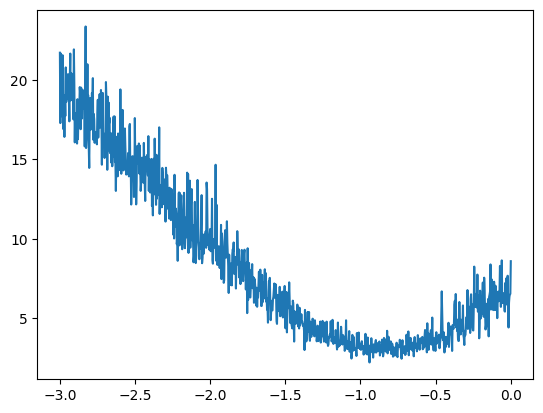

In [166]:
plt.plot(lri, lossi)

In [186]:
emb = C[
    X
]  # (32, 3, 2) 32 examples, 3 characters in context, 2-dimensional representation
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(
    logits, Y
)  # this is the same as the loss we calculated above, but more numerically stable
loss

tensor(2.3037, grad_fn=<NllLossBackward0>)

In [ ]:
# training split, dev/validation split, test split
# 80% training, 10% validation, 10% test